In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import confusion_matrix, classification_report

# Cấu hình hệ thống - Cập nhật cho B5
IMG_SIZE = (456, 456) 
BATCH_SIZE = 16 # Giảm batch size để tránh lỗi bộ nhớ (OOM) vì B5 nặng hơn B3
SEED = 123
DATA_DIR = '/kaggle/input/eye-diseases-classification/dataset' 

# Tải tập huấn luyện
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset='training', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

# Tải tập kiểm thử
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset='validation', seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

# Tối ưu hóa hiệu năng
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print(f"Danh sách các lớp: {class_names}")

2026-01-07 18:35:59.790834: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767810960.032275    2193 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767810960.113251    2193 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1767810960.720916    2193 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767810960.720954    2193 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767810960.720958    2193 computation_placer.cc:177] computation placer alr

Found 4217 files belonging to 4 classes.
Using 3374 files for training.


I0000 00:00:1767810970.044201    2193 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1767810970.048086    2193 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 4217 files belonging to 4 classes.
Using 843 files for validation.
Danh sách các lớp: ['cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


In [2]:
# Tăng cường dữ liệu
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.4),
])

# Khởi tạo mô hình gốc EfficientNetB5
base_model = tf.keras.applications.EfficientNetB5(
    input_shape=(456, 456, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False 

# Xây dựng cấu trúc tầng phân loại
inputs = layers.Input(shape=(456, 456, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(num_classes, activation='softmax')(x) 

model = models.Model(inputs, outputs)

# Callbacks
checkpoint = callbacks.ModelCheckpoint('best_eye_model_b5.keras', monitor='val_accuracy', save_best_only=True)
early_stopping = callbacks.EarlyStopping(patience=7, restore_best_weights=True)
lr_reducer = callbacks.ReduceLROnPlateau(factor=0.1, patience=3, min_lr=1e-7)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,529,915 (108.83 MB)

 Trainable params: 12,292 (48.02 KB)

 Non-trainable params: 28,517,623 (108.79 MB)

In [3]:
print("--- Giai đoạn 1: Huấn luyện Top Layers ---")
history = model.fit(train_ds, epochs=20, validation_data=val_ds, callbacks=[checkpoint, early_stopping, lr_reducer])

print("\n--- Giai đoạn 2: Fine-tuning toàn bộ mô hình ---")
base_model.trainable = True
# B5 có khoảng 570 lớp, đóng băng 300 lớp đầu là hợp lý
for layer in base_model.layers[:300]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), 
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_fine = model.fit(train_ds, epochs=18, validation_data=val_ds, callbacks=[checkpoint, early_stopping, lr_reducer])

--- Giai đoạn 1: Huấn luyện Top Layers ---
Epoch 1/20


E0000 00:00:1767810998.568184    2193 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb5_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1767811021.207292    2261 cuda_dnn.cc:529] Loaded cuDNN version 91002


211/211 ━━━━━━━━━━━━━━━━━━━━ 185s 661ms/step - accuracy: 0.4548 - loss: 1.4662 - val_accuracy: 0.6631 - val_loss: 0.8981 - learning_rate: 1.0000e-04
Epoch 2/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 135s 642ms/step - accuracy: 0.6541 - loss: 0.8862 - val_accuracy: 0.7248 - val_loss: 0.7025 - learning_rate: 1.0000e-04
Epoch 3/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 138s 656ms/step - accuracy: 0.6901 - loss: 0.8168 - val_accuracy: 0.7782 - val_loss: 0.6128 - learning_rate: 1.0000e-04
Epoch 4/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 139s 660ms/step - accuracy: 0.7215 - loss: 0.7439 - val_accuracy: 0.7841 - val_loss: 0.5991 - learning_rate: 1.0000e-04
Epoch 5/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 139s 661ms/step - accuracy: 0.7401 - loss: 0.6846 - val_accuracy: 0.8007 - val_loss: 0.5492 - learning_rate: 1.0000e-04
Epoch 6/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 140s 662ms/step - accuracy: 0.7540 - loss: 0.6269 - val_accuracy: 0.8031 - val_loss: 0.5464 - learning_rate: 1.0000e-04
Epoch 7/20
211/211 ━━━━━━━━━━━━━━━━━━━━ 138s 654ms/

E0000 00:00:1767813844.720445    2193 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb5_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


211/211 ━━━━━━━━━━━━━━━━━━━━ 312s 1s/step - accuracy: 0.6471 - loss: 0.9314 - val_accuracy: 0.8090 - val_loss: 0.5177 - learning_rate: 1.0000e-05
Epoch 2/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7764 - loss: 0.6117 - val_accuracy: 0.8031 - val_loss: 0.5325 - learning_rate: 1.0000e-05
Epoch 3/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.7876 - loss: 0.5802 - val_accuracy: 0.8114 - val_loss: 0.5073 - learning_rate: 1.0000e-05
Epoch 4/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.8172 - loss: 0.4776 - val_accuracy: 0.8327 - val_loss: 0.4530 - learning_rate: 1.0000e-05
Epoch 5/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.8374 - loss: 0.4621 - val_accuracy: 0.8517 - val_loss: 0.4102 - learning_rate: 1.0000e-05
Epoch 6/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.8388 - loss: 0.4339 - val_accuracy: 0.8624 - val_loss: 0.3957 - learning_rate: 1.0000e-05
Epoch 7/18
211/211 ━━━━━━━━━━━━━━━━━━━━ 258s 1s/step - accuracy: 0.87

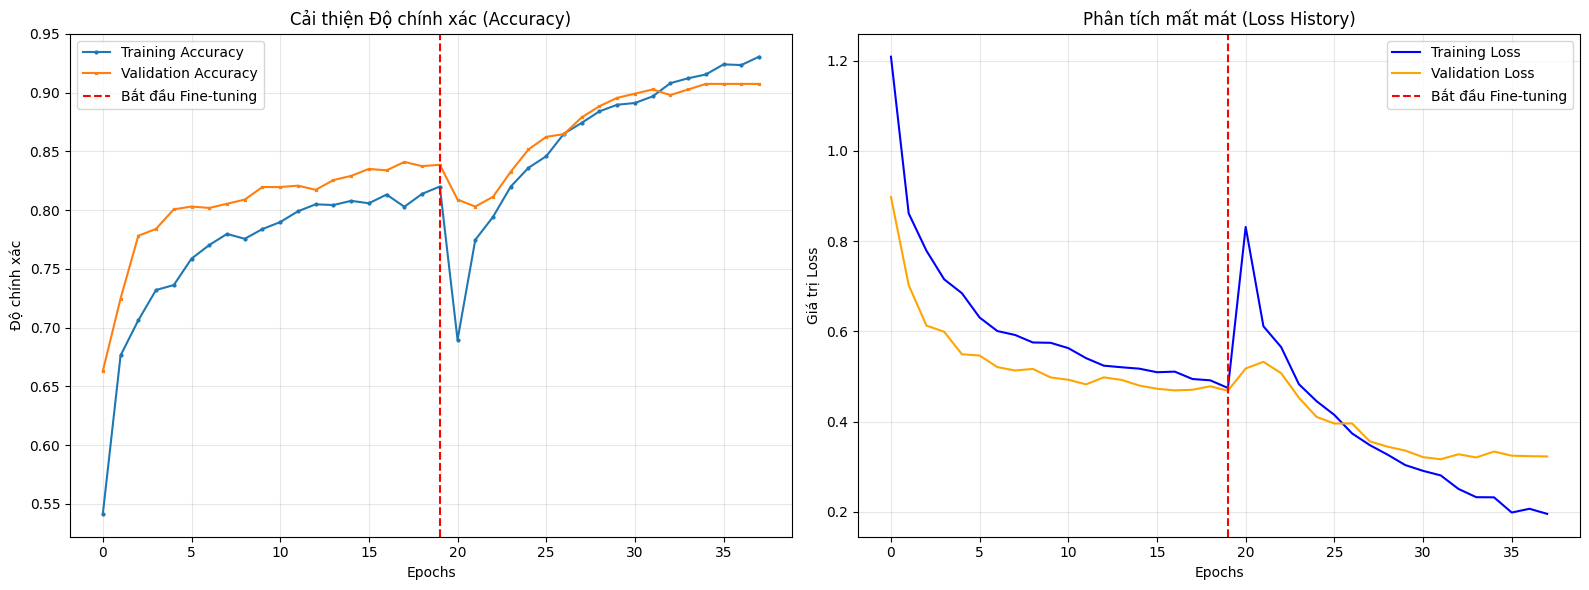

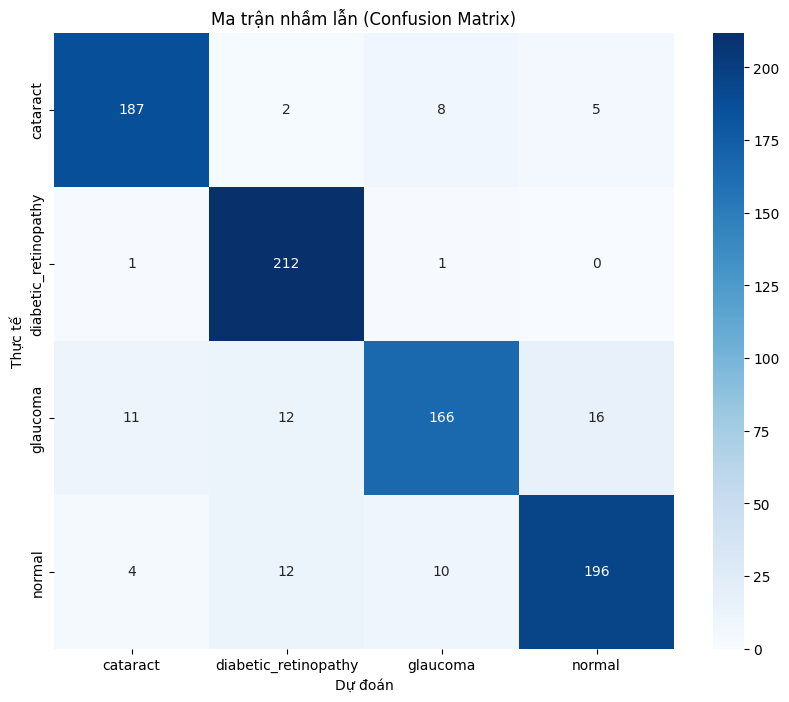

                      precision    recall  f1-score   support

            cataract       0.92      0.93      0.92       202
diabetic_retinopathy       0.89      0.99      0.94       214
            glaucoma       0.90      0.81      0.85       205
              normal       0.90      0.88      0.89       222

            accuracy                           0.90       843
           macro avg       0.90      0.90      0.90       843
        weighted avg       0.90      0.90      0.90       843



In [4]:
# Hiển thị biểu đồ Accuracy và Loss
def plot_full_history(history, history_fine):
    # Tổng hợp dữ liệu từ cả 2 giai đoạn
    acc = history.history['accuracy'] + history_fine.history['accuracy']
    val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
    loss = history.history['loss'] + history_fine.history['loss']
    val_loss = history.history['val_loss'] + history_fine.history['val_loss']

    # Điểm đánh dấu bắt đầu Fine-tuning
    tuning_point = len(history.history['accuracy']) - 1

    plt.figure(figsize=(16, 6))

    # --- BIỂU ĐỒ ACCURACY ---
    plt.subplot(1, 2, 1)
    plt.plot(acc, label='Training Accuracy', marker='o', markersize=2)
    plt.plot(val_acc, label='Validation Accuracy', marker='x', markersize=2)
    plt.axvline(tuning_point, color='red', linestyle='--', label='Bắt đầu Fine-tuning')
    plt.title('Cải thiện Độ chính xác (Accuracy)')
    plt.xlabel('Epochs')
    plt.ylabel('Độ chính xác')
    plt.grid(True, alpha=0.3)
    plt.legend()

    # --- BIỂU ĐỒ LOSS (MẤT MÁT) ---
    plt.subplot(1, 2, 2)
    plt.plot(loss, label='Training Loss', color='blue')
    plt.plot(val_loss, label='Validation Loss', color='orange')
    plt.axvline(tuning_point, color='red', linestyle='--', label='Bắt đầu Fine-tuning')
    
    # Giới hạn trục Y để dễ quan sát nếu Loss ban đầu quá cao
    if max(val_loss) > 2.0:
        plt.ylim(0, 2.0)
        
    plt.title('Phân tích mất mát (Loss History)')
    plt.xlabel('Epochs')
    plt.ylabel('Giá trị Loss')
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

# Gọi hàm hiển thị biểu đồ
plot_full_history(history, history_fine)

# --- MA TRẬN NHẦM LẪN ---
y_true, y_pred = [], []
for x_batch, y_batch in val_ds:
    y_true.extend(y_batch.numpy())
    y_pred.extend(np.argmax(model.predict(x_batch, verbose=0), axis=1))

plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

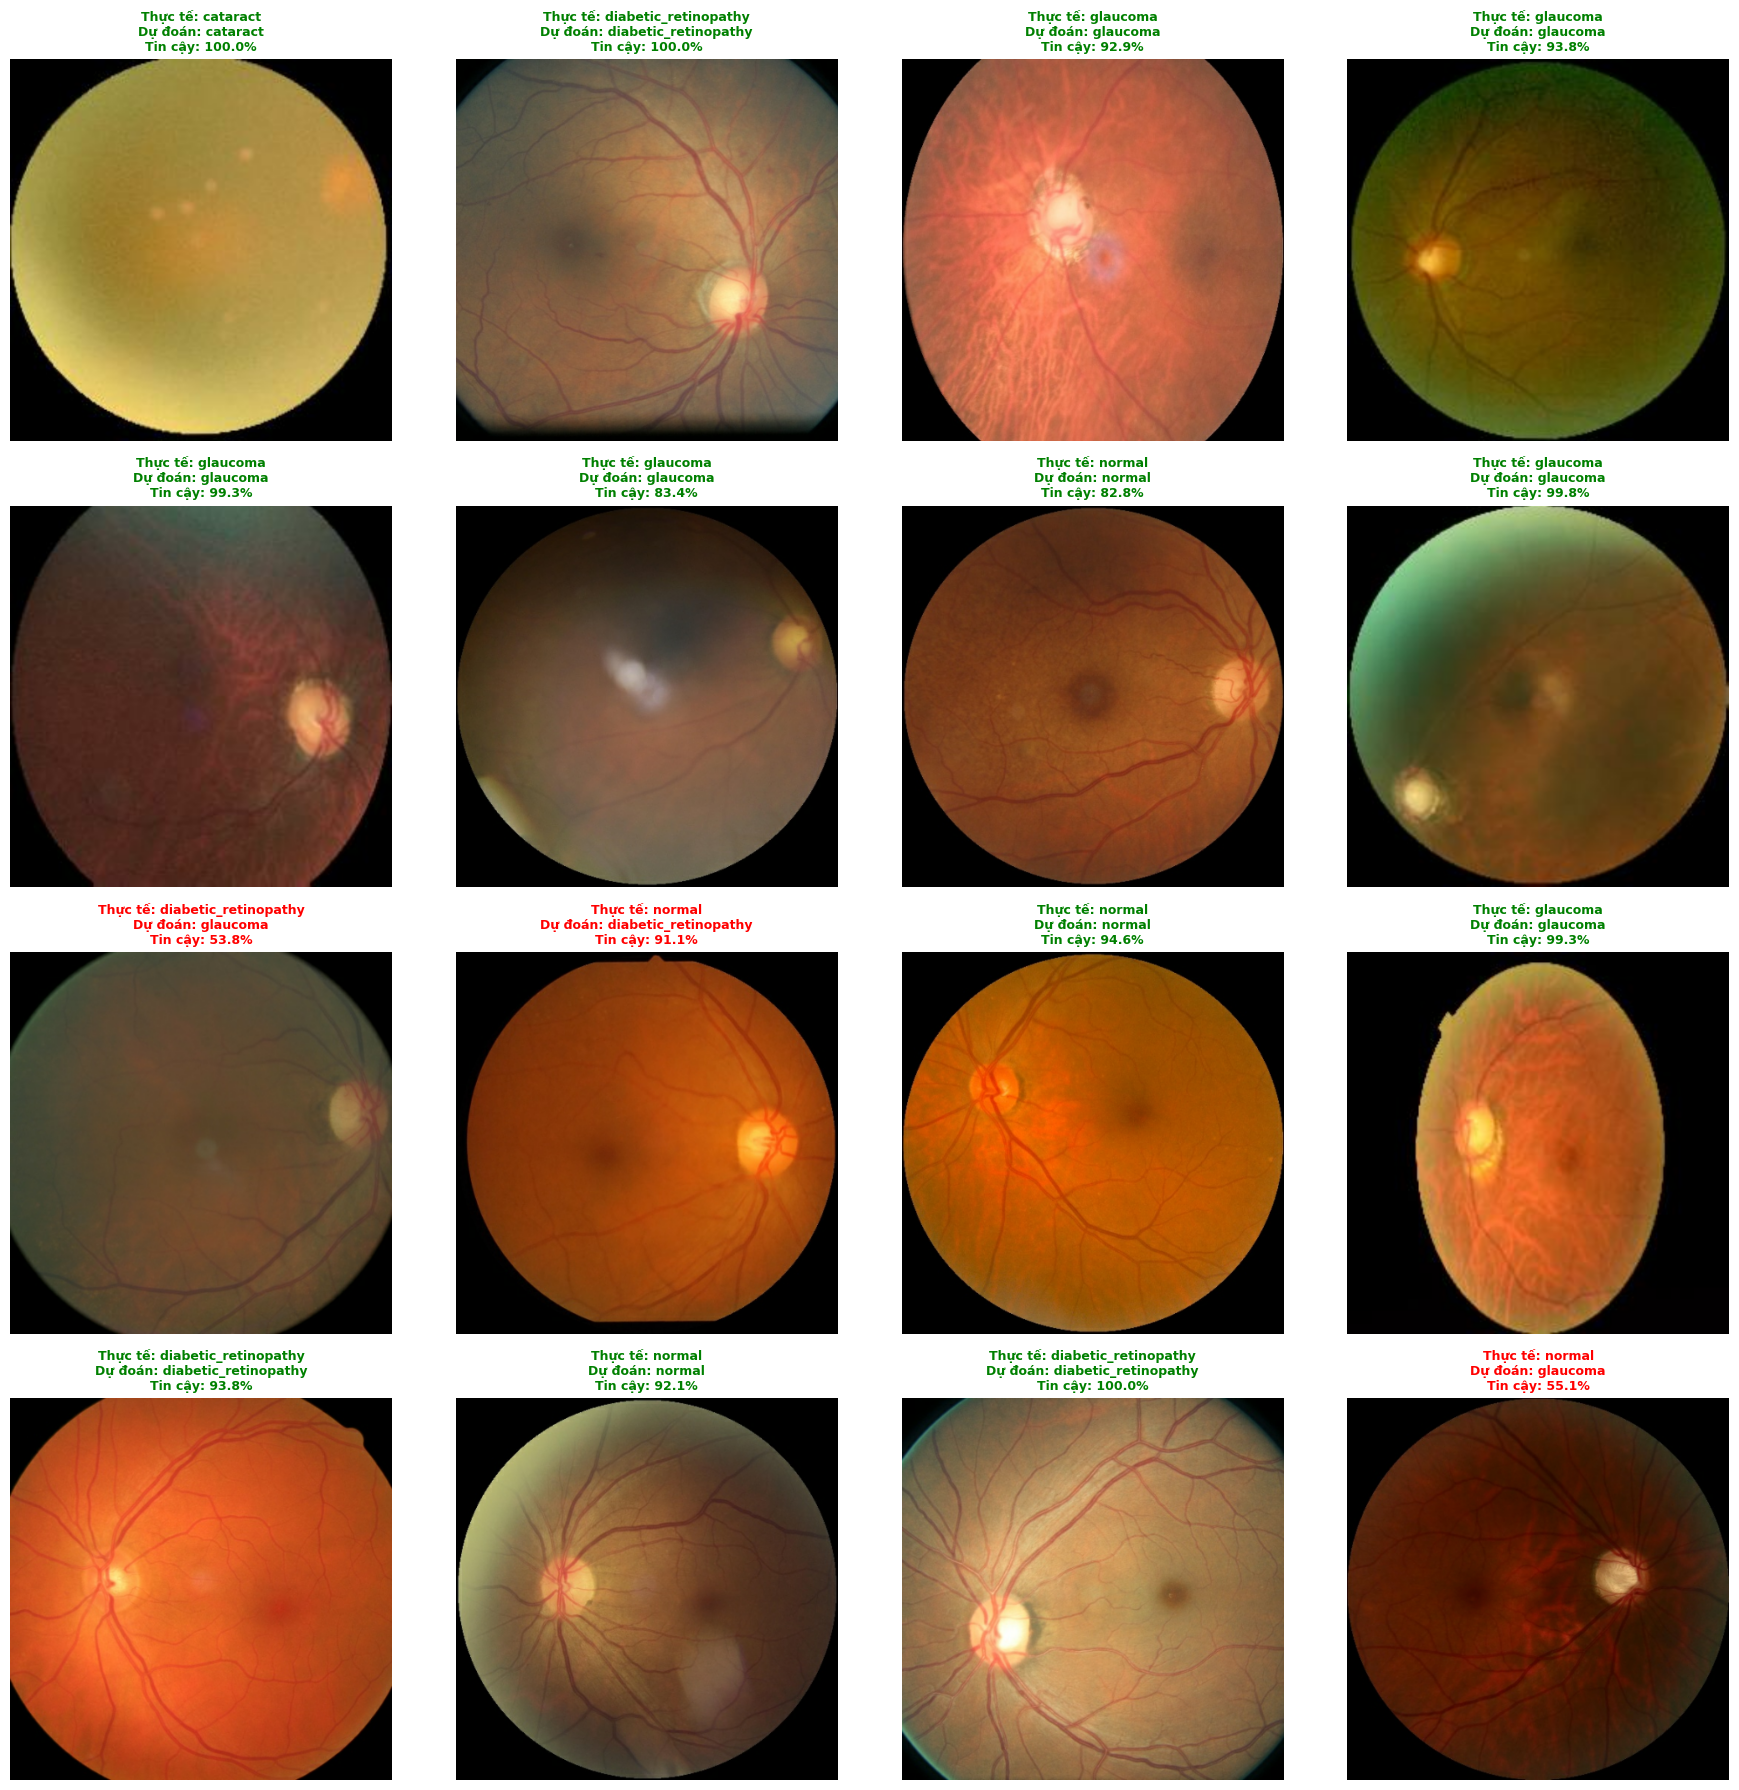

In [5]:
def predict_medical_precision(model, img_array, threshold= 30.0, diabetic_limit=0.3):
    img_batch = np.expand_dims(img_array, 0)
    predictions = model.predict(img_batch, verbose=0)[0]
    
    # Lấy thông tin dự đoán cao nhất thông thường
    max_idx = np.argmax(predictions)
    confidence = predictions[max_idx] * 100
    predicted_class = class_names[max_idx]
    
    # Chỉ số của lớp tiểu đường
    idx_diabetic = class_names.index('diabetic_retinopathy')
    prob_diabetic = predictions[idx_diabetic]
    
    # --- LOGIC ƯU TIÊN AN TOÀN ---
    # 1. Nếu xác suất tiểu đường > ngưỡng nghi ngờ (ví dụ 30%), ưu tiên cảnh báo luôn
    if prob_diabetic > diabetic_limit and predicted_class != 'diabetic_retinopathy':
        return f"Nghi ngờ Tiểu đường", prob_diabetic * 100, "warning"
    
    # 2. Nếu độ tự tin chung quá thấp
    if confidence < threshold:
        return "Cần kiểm tra lại", confidence, "uncertain"
    
    # 3. Kết quả bình thường
    return predicted_class, confidence, "normal"

# Hiển thị kết quả Test
plt.figure(figsize=(18, 18))
for images, labels in val_ds.take(1):
    for i in range(16):
        plt.subplot(4, 4, i+1)
        img_np = images[i].numpy().astype("uint8")
        plt.imshow(img_np)
        
        actual = class_names[labels[i]]
        p_class, conf, status = predict_medical_precision(model, img_np)
        
        # Xác định màu sắc tiêu đề
        if status == "warning":
            color = 'orange' # Màu cam cho trường hợp nghi ngờ
        elif status == "uncertain":
            color = 'gray'   # Màu xám cho trường hợp không chắc chắn
        else:
            color = 'green' if p_class == actual else 'red' # Xanh nếu đúng, Đỏ nếu sai
            
        plt.title(f"Thực tế: {actual}\nDự đoán: {p_class}\nTin cậy: {conf:.1f}%", 
                  color=color, fontsize=9, fontweight='bold')
        plt.axis('off')

plt.tight_layout()
plt.show()